In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

----

# Simple Linear Regression using Numpy `np.polyfit`
Simple linear regression uses **only one** independent variable(Feature) to explain/predict the dependent variable (label)

In [20]:
df = pd.read_csv(r"C:\Users\Olade\Documents\Python Notebooks\UNZIP_FOR_NOTEBOOKS_FINAL\08-Linear-Regression-Models\Advertising.csv")

In [4]:
df.head()

,TV,radio,newspaper,sales
0,230.1,37.8,69.2,22.1
1,44.5,39.3,45.1,10.4
2,17.2,45.9,69.3,9.3
3,151.5,41.3,58.5,18.5
4,180.8,10.8,58.4,12.9


In [5]:
df['total_ads_spend'] = df['TV'] + df['radio'] + df['newspaper']

In [6]:
df.head()

,TV,radio,newspaper,sales,total_ads_spend
0,230.1,37.8,69.2,22.1,337.1
1,44.5,39.3,45.1,10.4,128.9
2,17.2,45.9,69.3,9.3,132.4
3,151.5,41.3,58.5,18.5,251.3
4,180.8,10.8,58.4,12.9,250.0


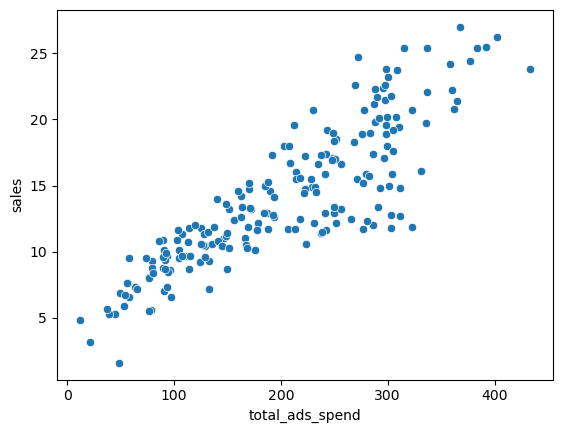

In [7]:
sns.scatterplot(data=df, x='total_ads_spend', y='sales');

In [8]:
# sns.regplot(data=df, x='total_ads_spend', y='sales');

In [9]:
X = df['total_ads_spend']
y = df['sales']

In [10]:
slope, intercept = np.polyfit(X,y,deg=1)

In [11]:
potential_ads_spend = np.linspace(0,500,100) # The range of the total_ads_spend in the df

In [12]:
predicted_sales = slope*potential_ads_spend + intercept

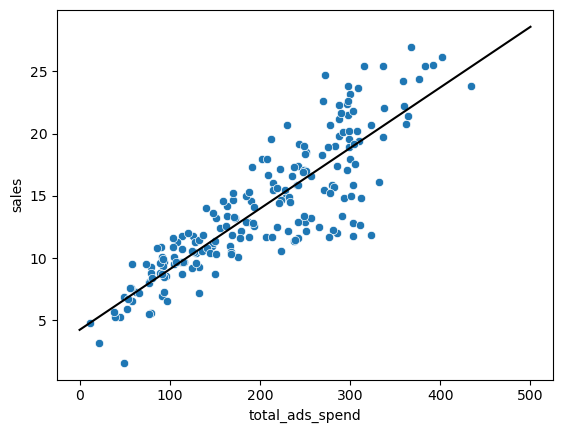

In [13]:
sns.scatterplot(data=df, x='total_ads_spend', y='sales')
sns.lineplot(x=potential_ads_spend, y=predicted_sales, color='black');

**Given a total ads spend of 200, what is the value of the predicted sales?**

In [14]:
spend = 200
predicted_sales = slope*spend + intercept

In [15]:
predicted_sales

np.float64(13.98060407984596)

### Polynomial regression

In [16]:
b3,b2,b1,b0 = np.polyfit(X,y,deg=3)

In [17]:
pred_sales = b3*potential_ads_spend**3 + b2*potential_ads_spend**2 + b1*potential_ads_spend + b0

<Axes: xlabel='total_ads_spend', ylabel='sales'>

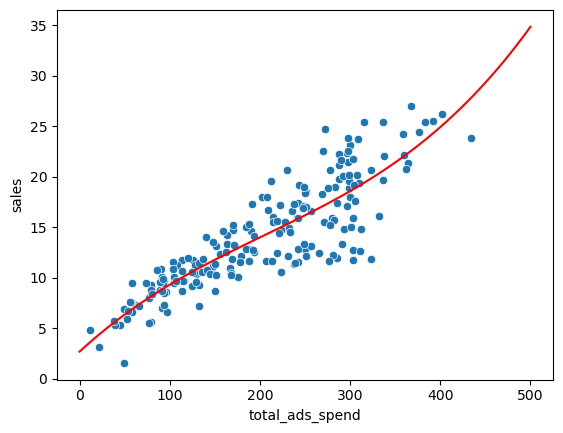

In [18]:
sns.lineplot(x=potential_ads_spend, y=pred_sales, color='red')
sns.scatterplot(data=df, x='total_ads_spend', y='sales')

**Limitations of `np.polyfit`**
- Linear/Polynomial regression of one independent variable
- No built-in method to evaluate the performance of fitted lines. (Is the curved fit better than the linear fit?)
- No information of statistical coefficients such as **P-values**, **R-squared**, **Standard errors** etc
----

----
# Linear Regression using Scikit-learn
With Scikit-learn, it is possible to evaluate the relationship between **multiple** independent variables (Features) and the dependent variable (label)

- from sklearn.model_selection import train_test_split
- from sklearn.linear_model import LinearRegression
- from sklearn.metrics import mean_absolute_error, mean_squared_error

In [22]:
df = pd.read_csv(r"C:\Users\Olade\Documents\Python Notebooks\UNZIP_FOR_NOTEBOOKS_FINAL\08-Linear-Regression-Models\Advertising.csv")
df.head()

,TV,radio,newspaper,sales
0,230.1,37.8,69.2,22.1
1,44.5,39.3,45.1,10.4
2,17.2,45.9,69.3,9.3
3,151.5,41.3,58.5,18.5
4,180.8,10.8,58.4,12.9


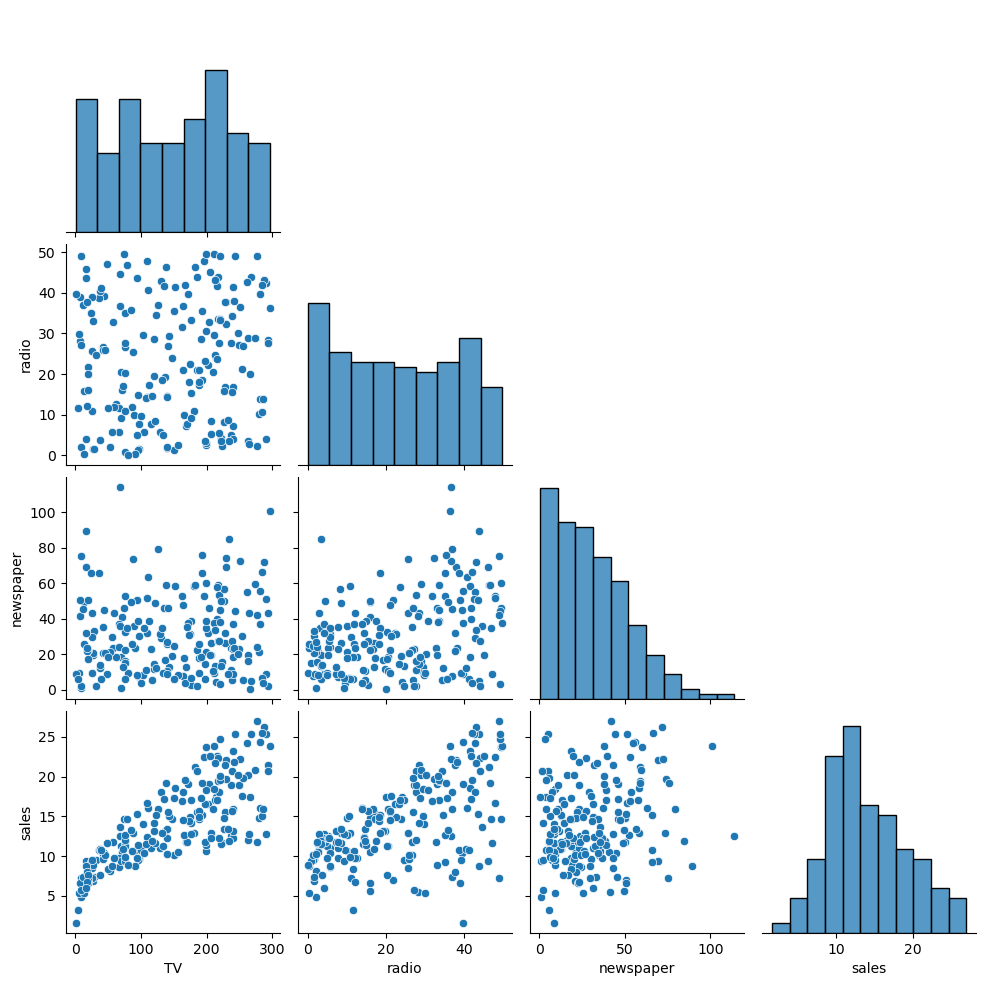

In [25]:
sns.pairplot(data=df, corner=True)

In [29]:
# Separate the data into features and label
X = df.drop('sales', axis=1) 
X

,TV,radio,newspaper
0,230.1,37.8,69.2
1,44.5,39.3,45.1
2,17.2,45.9,69.3
3,151.5,41.3,58.5
4,180.8,10.8,58.4
...,...,...,...
195,38.2,3.7,13.8
196,94.2,4.9,8.1
197,177.0,9.3,6.4
198,283.6,42.0,66.2


In [31]:
y = df[['sales']]
y

,sales
0,22.1
1,10.4
2,9.3
3,18.5
4,12.9
...,...
195,7.6
196,9.7
197,12.8
198,25.5


In [32]:
from sklearn.model_selection import train_test_split

In [34]:
# help(train_test_split)

In [35]:
 X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=101)

In [40]:
X_train.head()

,TV,radio,newspaper
85,193.2,18.4,65.7
183,287.6,43.0,71.8
127,80.2,0.0,9.2
53,182.6,46.2,58.7
100,222.4,4.3,49.8


In [41]:
y_train.head()

,sales
85,15.2
183,26.2
127,8.8
53,21.2
100,11.7


In [42]:
from sklearn.linear_model import LinearRegression

In [44]:
# help(LinearRegression)

In [45]:
model = LinearRegression()

In [46]:
model.fit(X_train, y_train)

LinearRegression()

In [48]:
test_predictions = model.predict(X_test)

### Performance evaluation of Scikit-learn predictions

In [49]:
from sklearn.metrics import mean_absolute_error, mean_squared_error

In [50]:
df['sales'].mean()

np.float64(14.0225)

In [51]:
y_test.std()

sales    5.358234
dtype: float64

<Axes: xlabel='sales', ylabel='Count'>

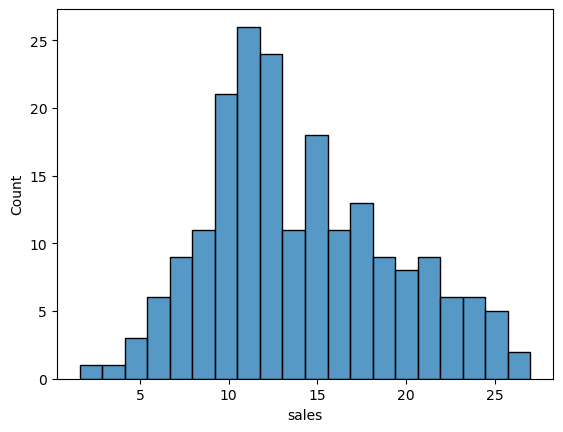

In [52]:
sns.histplot(data=df, x='sales', bins=20)

In [53]:
mean_absolute_error(y_test, test_predictions)

1.2137457736144803

In [56]:
# RMSE - Root Mean Squared Error
np.sqrt(mean_squared_error(y_test, test_predictions))

np.float64(1.516151937599388)

When RMSE is considerably larger than MAE, it suggests that the model has some relatively large errors compared with its typical error.

- MAE tells you the average magnitude of prediction errors.
- RMSE tells you more about the impact of large prediction errors.
- The ratio RMSE/MAE can help assess how pronounced those large errors are.